In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)


In [2]:
POLLUTANT = "pm25"
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
TEST_FRACTION = 0.2

PROCESSED_DIR = Path("../data/processed")
FEATURES_FILE = PROCESSED_DIR / f"features_{POLLUTANT}.parquet"
TARGET = f"{POLLUTANT}_high"

In [3]:
df = pd.read_parquet(FEATURES_FILE)
df["date"] = pd.to_datetime(df["date"])

In [4]:
lag_cols = [f"{POLLUTANT}_lag_{d}" for d in LAGGED_DAYS]
rolling_cols = [f"{POLLUTANT}_rolling_{w}" for w in ROLLING_WINDOWS]
rolling_std_cols = [f"{POLLUTANT}_rolling_std_{w}" for w in ROLLING_WINDOWS]
calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
weather_cols = [
    col for col in df.columns
    if (col.startswith(("temperature", "relative_humidity", "dew_point",
                        "apparent_temperature", "pressure", "surface_pressure",
                        "precipitation", "rain_sum", "snowfall", "cloud_cover",
                        "shortwave", "direct_radiation", "diffuse_radiation",
                        "global_tilted", "sunshine", "wind", "et0",
                        "weather_code", "snow_depth", "vapour_pressure", "soil_"))
        and col != "wind_category")
]

In [5]:
base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
required = base_cols + ["date", "station_id", TARGET]

model_df = df.dropna(subset=required).copy().reset_index(drop=True)
model_df = model_df.sort_values("date").reset_index(drop=True)

In [6]:
wind_dummies = pd.get_dummies(model_df["wind_category"], prefix="wind")

display(pd.concat([model_df[[c for c in model_df.columns if c.startswith("wind")]],
                   wind_dummies],
                  axis=1).head(10))

,wind_speed_10m_mean,wind_speed_10m_max,wind_speed_100m_mean,wind_speed_100m_max,wind_gusts_10m_max,wind_direction_10m_mean,wind_direction_100m_mean,wind_category,wind_weak,wind_moderate,wind_strong
0,1.357500,3.73,1.962083,4.66,9.8,212.833333,199.833333,weak,True,False,False
1,1.357500,3.73,1.962083,4.66,9.8,212.833333,199.833333,weak,True,False,False
2,1.361250,2.37,1.733333,3.21,6.5,208.416667,210.833333,weak,True,False,False
3,1.361250,2.37,1.733333,3.21,6.5,208.416667,210.833333,weak,True,False,False
4,1.933333,5.16,3.104167,7.13,13.0,150.541667,160.541667,weak,True,False,False
5,1.933333,5.16,3.104167,7.13,13.0,150.541667,160.541667,weak,True,False,False
6,2.504167,5.25,3.834583,7.57,13.7,170.666667,107.583333,moderate,False,True,False
7,2.504167,5.25,3.834583,7.57,13.7,170.666667,107.583333,moderate,False,True,False
8,1.861667,4.03,2.481250,5.05,10.2,111.666667,89.083333,weak,True,False,False
9,1.861667,4.03,2.481250,5.05,10.2,111.666667,89.083333,weak,True,False,False


In [7]:
X = pd.concat([model_df[base_cols].reset_index(drop=True), wind_dummies.reset_index(drop=True)], axis=1).astype(float)
y = model_df[TARGET].astype(int)

split_idx = int(len(model_df) * (1 - TEST_FRACTION))
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

In [8]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

In [9]:
print(f"Modelling rows: {len(model_df):,}")
print(f"Positive (high) rate overall: {y.mean():.3f}")
print(f"Positive rate test: {y_test.mean():.3f}")
print(f"Train period: {model_df['date'].iloc[0].date()} .. {model_df['date'].iloc[split_idx-1].date()}")
print(f"Test period : {model_df['date'].iloc[split_idx].date()} .. {model_df['date'].iloc[-1].date()}")

Modelling rows: 1,912
Positive (high) rate overall: 0.336
Positive rate test: 0.319
Train period: 2018-04-26 .. 2024-07-19
Test period : 2024-07-19 .. 2025-12-31


In [10]:
def evaluate_classification(y_true, y_pred, y_proba):
    return {
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "F1": float(f1_score(y_true, y_pred, zero_division=0)),
        "ROC_AUC": float(roc_auc_score(y_true, y_proba)),
    }


In [ ]:
# Majority
baseline_pred = pd.Series(y_test.mode()[0], index=y_test.index)
baseline_proba = pd.Series(y_test.mode()[0], index=y_test.index)
baseline_metrics = evaluate_classification(y_test, baseline_pred, baseline_proba)

In [12]:
models = {
    "LogisticRegression": (LogisticRegression(max_iter=2000, class_weight="balanced"), X_train_s, X_test_s),
    "RandomForest": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced"), X_train, X_test),
    "GradientBoosting": (GradientBoostingClassifier(random_state=42), X_train, X_test),
}

In [13]:
results = {}
predictions = {}
probabilities = {}
for name, (model, xtr, xte) in models.items():
    model.fit(xtr, y_train)
    pred = model.predict(xte)
    proba = model.predict_proba(xte)[:, 1]
    results[name] = evaluate_classification(y_test, pred, proba)
    predictions[name] = pred
    probabilities[name] = proba

results["MajorityClass"] = baseline_metrics
results_df = pd.DataFrame(results).T
results_df = results_df.reindex(results_df["F1"].sort_values(ascending=False).index)
display(results_df.round(3))


,Accuracy,Precision,Recall,F1,ROC_AUC
RandomForest,0.893,0.768,0.951,0.850,0.965
LogisticRegression,0.880,0.735,0.975,0.838,0.957
GradientBoosting,0.875,0.747,0.918,0.824,0.948
MajorityClass,0.681,0.000,0.000,0.000,0.500


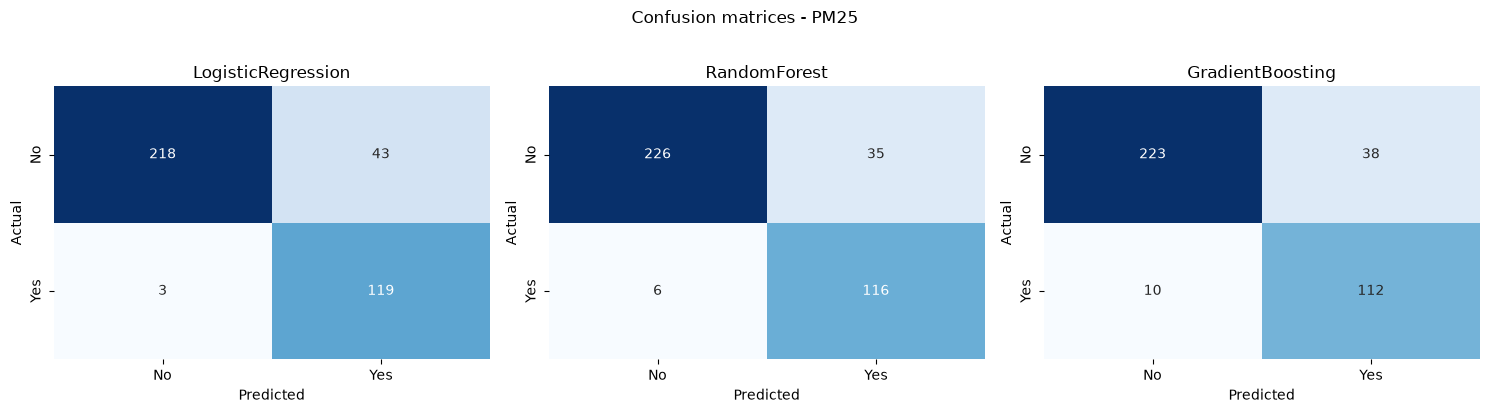

In [15]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))
best_cls = results_df.loc[~results_df.index.isin(["MajorityClass"]), "F1"].idxmax()
for ax, (name, (model, _, _)) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.suptitle(f"Confusion matrices - {POLLUTANT.upper()}", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
comparison = pd.DataFrame({"date": model_df["date"].iloc[split_idx:].reset_index(drop=True),
                             "station_id": model_df["station_id"].iloc[split_idx:].reset_index(drop=True),
                             "y_test": y_test.reset_index(drop=True)})
for name, pred in predictions.items():
    comparison[name + "_pred"] = pred
    comparison[name + "_proba"] = probabilities[name]

print(f"Best classifier by F1: {best_cls}")
display(comparison.head(10))

NameError: name 'pd' is not defined

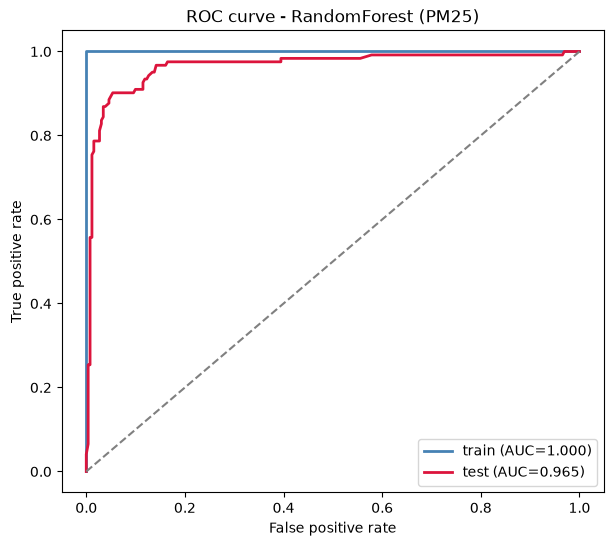

In [17]:
best_cls_model = models[best_cls][0]
proba_train = best_cls_model.predict_proba(X_train_s if best_cls == "LogisticRegression" else X_train)[:, 1]
proba_test = probabilities[best_cls]
_, ax = plt.subplots(figsize=(7, 6))
for label, proba, color in [("train", proba_train, "steelblue"), ("test", proba_test, "crimson")]:
    fpr, tpr, _ = roc_curve(y_train if label == "train" else y_test, proba)
    ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_train if label=='train' else y_test, proba):.3f})", color=color, linewidth=2)
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(f"ROC curve - {best_cls} ({POLLUTANT.upper()})")
ax.legend()
plt.show()

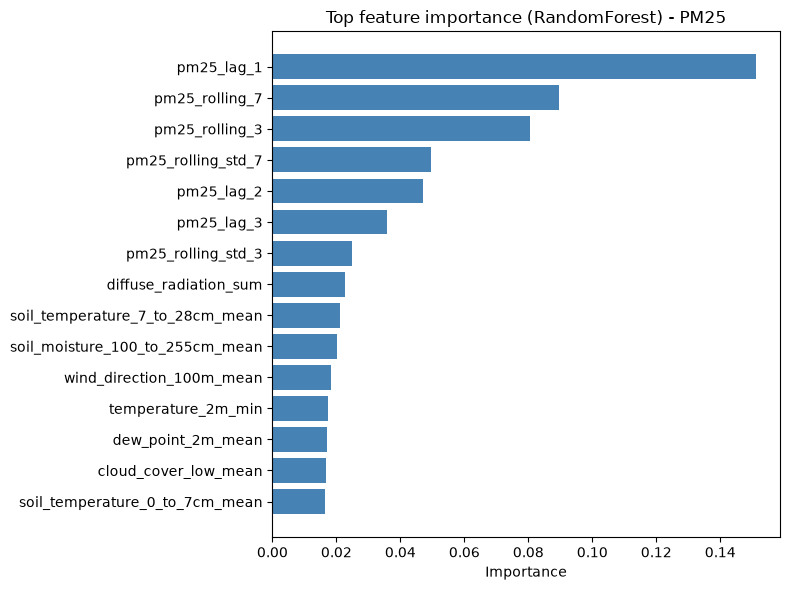

In [18]:
if hasattr(best_cls_model, "feature_importances_"):
    importances = best_cls_model.feature_importances_
    imp_df = pd.DataFrame({"feature": X.columns, "importance": importances}).sort_values("importance", ascending=False)
    plt.figure(figsize=(8, 6))
    plot_df = imp_df.head(15).iloc[::-1]
    plt.barh(plot_df["feature"], plot_df["importance"], color="steelblue")
    plt.xlabel("Importance")
    plt.title(f"Top feature importance ({best_cls}) - {POLLUTANT.upper()}")
    plt.tight_layout()
    plt.show()


Most of the features shown here are the lag features, lets try to group them

In [19]:
if hasattr(best_cls_model, "feature_importances_"):
    importance = best_cls_model.feature_importances_
else:
    importance = np.abs(best_cls_model.coef_)
feature_names = list(X.columns)

In [20]:
FACTOR_GROUPS = {
    "Previous pollution (lag)": [f"{POLLUTANT}_lag_{d}" for d in LAGGED_DAYS],
    "Previous pollution (rolling)": [f"{POLLUTANT}_rolling_{w}" for w in ROLLING_WINDOWS] + [f"{POLLUTANT}_rolling_std_{w}" for w in ROLLING_WINDOWS],
    "Temperature": [c for c in feature_names if "temperature" in c or "dew_point" in c],
    "Humidity": [c for c in feature_names if "humidity" in c or "vapour_pressure" in c],
    "Wind": [c for c in feature_names if "wind" in c and "category" not in c] + [c for c in feature_names if c.startswith("wind_")],
    "Precipitation": [c for c in feature_names if "precip" in c or "rain" in c or "snowfall" in c or "snow_depth" in c],
    "Pressure": [c for c in feature_names if "pressure" in c],
    "Clouds & radiation": [c for c in feature_names if "cloud" in c or "radiation" in c or "sunshine" in c or "et0" in c],
    "Season / calendar": [c for c in feature_names if "month" in c or "dow" in c or "weekend" in c],
    "Soil": [c for c in feature_names if c.startswith("soil")],
    "Wind category": [c for c in feature_names if c.startswith("wind_weak") or c.startswith("wind_moderate") or c.startswith("wind_strong")],
    "Weather code": [c for c in feature_names if "weather_code" in c],
}

In [21]:
factor_importance = []
for factor, cols in FACTOR_GROUPS.items():
    present = [c for c in cols if c in feature_names]
    if not present:
        continue
    vals = [importance[list(feature_names).index(c)] for c in present]
    factor_importance.append({
        "factor": factor,
        "n_features": len(present),
        "importance_max": float(np.max(vals)),
        "importance_mean": float(np.mean(vals)),
    })

In [22]:
factor_df = pd.DataFrame(factor_importance).sort_values("importance_mean", ascending=False)
display(factor_df.round(4))

,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.1511,0.0779
1,Previous pollution (rolling),4,0.0895,0.0611
9,Soil,8,0.0212,0.0154
2,Temperature,9,0.0212,0.0148
7,Clouds & radiation,9,0.0227,0.0129
3,Humidity,4,0.0104,0.0094
6,Pressure,5,0.0101,0.0088
4,Wind,20,0.0184,0.0080
8,Season / calendar,5,0.0142,0.0049
5,Precipitation,5,0.0076,0.0043


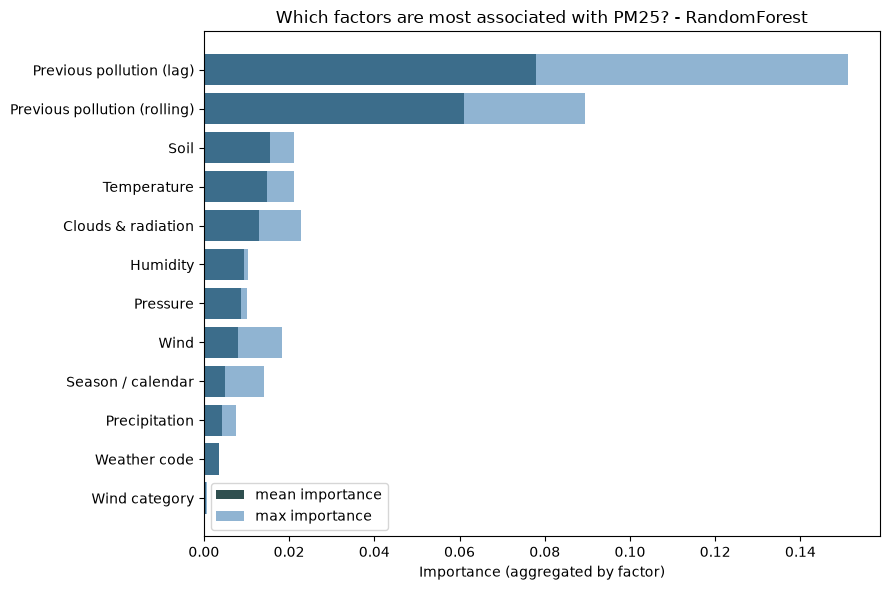

In [23]:
plt.figure(figsize=(9, 6))
plot_df = factor_df.iloc[::-1]
plt.barh(plot_df["factor"], plot_df["importance_mean"], color="darkslategray", label="mean importance")
plt.barh(plot_df["factor"], plot_df["importance_max"], color="steelblue", alpha=0.6, label="max importance")
plt.xlabel("Importance (aggregated by factor)")
plt.title(f"Which factors are most associated with {POLLUTANT.upper()}? - {best_cls}")
plt.legend()
plt.tight_layout()
plt.show()


In [24]:
METRICS_OUT = PROCESSED_DIR / f"classification_metrics_{POLLUTANT}.parquet"
PRED_OUT = PROCESSED_DIR / f"classification_predictions_{POLLUTANT}.parquet"
PROBA_OUT = PROCESSED_DIR / f"classification_probabilities_{POLLUTANT}.parquet"

In [25]:
results_df.to_parquet(METRICS_OUT)
comparison.to_parquet(PRED_OUT, index=False)
proba_df = pd.DataFrame(probabilities)
proba_df["date"] = model_df["date"].iloc[split_idx:].reset_index(drop=True)
proba_df["station_id"] = model_df["station_id"].iloc[split_idx:].reset_index(drop=True)
proba_df.to_parquet(PROBA_OUT, index=False)
print(f"Saved: {METRICS_OUT.name}")
print(f"Saved: {PRED_OUT.name}")
print(f"Saved: {PROBA_OUT.name}")


Saved: classification_metrics_pm25.parquet
Saved: classification_predictions_pm25.parquet
Saved: classification_probabilities_pm25.parquet
